In [2]:
import numpy as np
import matplotlib.pyplot as plt

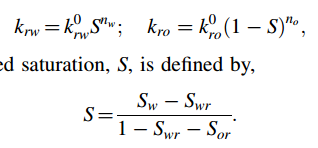

## Burdine integrated Brooks-Corey model

In [5]:
Swr = 0.1
Snwr = 0.2
krwo = 0.3
krnwo = 0.8
lambda_ = 2

Sw = np.linspace(start=Swr, stop=1-Snwr, num=100)
Swd = (Sw - Swr) / (1 - Swr - Snwr)

krw  = krwo  * Swd**(2/lambda_ + 3)
krnw = krnwo * (1 - Swd)**2 * (1 - Swd**(2/lambda_ + 1))

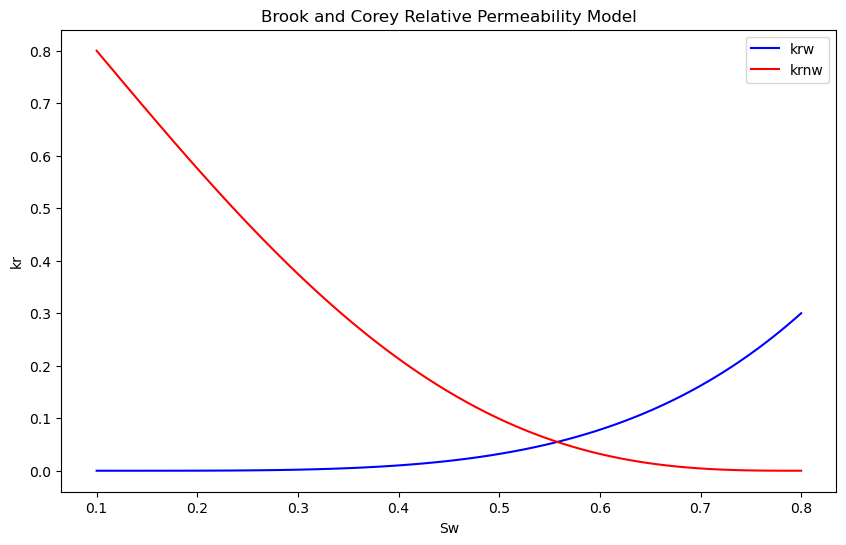

In [8]:
plt.figure(figsize=(10, 6))
plt.plot(Sw, krw, label='krw', color='blue')
plt.plot(Sw, krnw, label='krnw', color='red')
plt.xlabel('Sw')
plt.ylabel('kr')
plt.title('Brook and Corey Relative Permeability Model')
plt.legend()
plt.show()

## Modified Brooks-Corey model

In [25]:
Swr = 0.1
Snwr = 0.2
krwo = 0.3
krnwo = 0.8
nw = 2
nnw = 2

Sw = np.linspace(start=Swr, stop=1-Snwr, num=100)
Swd = (Sw - Swr) / (1 - Swr - Snwr)

krw  = krwo  * Swd**(nw)
krnw = krnwo * (1 - Swd)**nnw

In [32]:
Sw.shape

(100,)

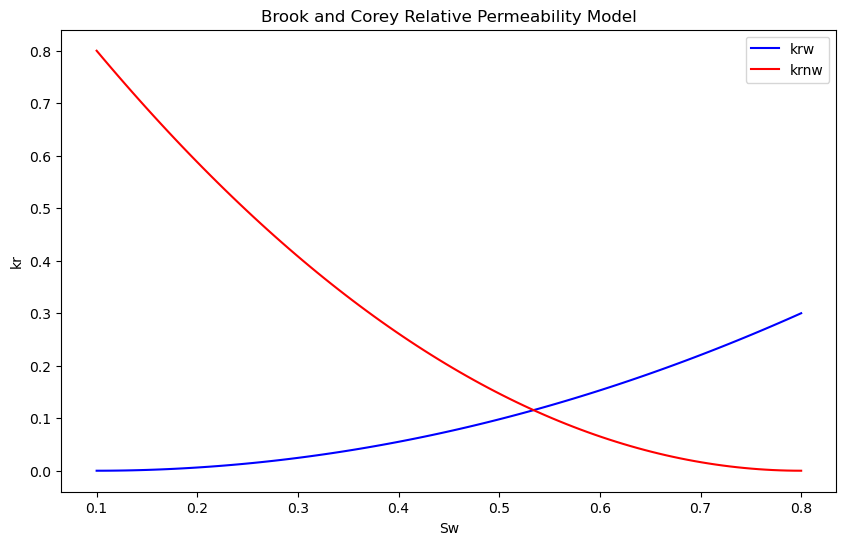

In [31]:
plt.figure(figsize=(10, 6))
plt.plot(Sw, krw, label='krw', color='blue')
plt.plot(Sw, krnw, label='krnw', color='red')
plt.xlabel('Sw')
plt.ylabel('kr')
plt.title('Brook and Corey Relative Permeability Model')
plt.legend()
plt.show()

## Stone Model I

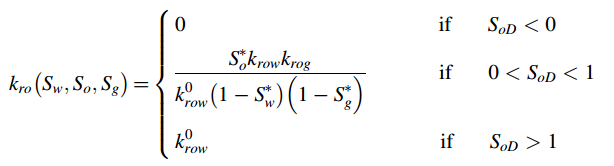

In [32]:


Swr = 0.1
Sgr = 0.05
Sor_ow = 0.4 # oil residual saturation in oil-water system
Sor_og = 0.2 # oil residual saturation in oil-gas system
# Slr_og = Sor_og + Swr # residual saturation of liquid in oil-gas system
# Slr_ow = Sor_ow + Swr # residual saturation of liquid in oil-water system

kro_ow = 0.8
kro_og = 0.8
krwo = 0.3
krgo = 0.3

nw = 2
nog = 2
now = 2
ng = 2

n = 101
Sw_1d = np.linspace(Swr, 1.0, n)
Sg_1d = np.linspace(0.0, 1.0 - Swr, n)

SW, SG = np.meshgrid(Sw_1d, Sg_1d)

SO = 1.0 - SW - SG
valid = SO >= -1e-12  # keep points with Sw + Sg <= 1

valid = SO >= -1e-12  # keep points with Sw + Sg <= 1
Sw, Sg, So = SW[valid], SG[valid], np.clip(SO[valid], 0.0, 1.0)

Swd = np.clip((Sw - Swr) / (1 - Swr - Sor_ow), 0, 1)
Sgd = np.clip((Sg - Sgr) / (1 - Swr - Sor_og - Sgr), 0, 1)

Sod = (So - Sor_ow) / (1 - Sgr - Sor_ow - Swr)
# or
# Sod = (So - Sor_og) / (1 - Sgr - Slr_og)

krw  = krwo * Swd**(nw)
krg = krgo * Sgd**(ng)
krow = kro_ow * (1 - Swd)**(now)
krog = kro_og * (1 - Sgd)**(nog)

a = np.clip(Sg/(1 - Swr - Sor_og), 0, 1)
Som = (1-a)*Sor_ow + a*Sor_og
Sw_star = (Sw - Swr) / (1 - Swr - Som)
So_star = (So - Som) / (1 - Swr - Som) #So<Som is possible, so kro can be negative, it will be set to 0 in that case
Sg_star = Sg / (1 - Swr - Som)
# Sw* + So* + Sg* = 1

# When So* is 0, denominator is 0, so we use np.where to avoid division by zero making kro = 0 in that case
denominator = np.where(So_star>0, (1-Sw_star)*(1-Sg_star), 1)
# When So<Som, kro can be negative, so we set it to 0 in that case
stone = np.where(So_star>0, (So_star*krow*krog)/(kro_ow*denominator), 0)
kro = np.where(Sod < 0,  0, np.where(Sod > 1, kro_ow, stone))

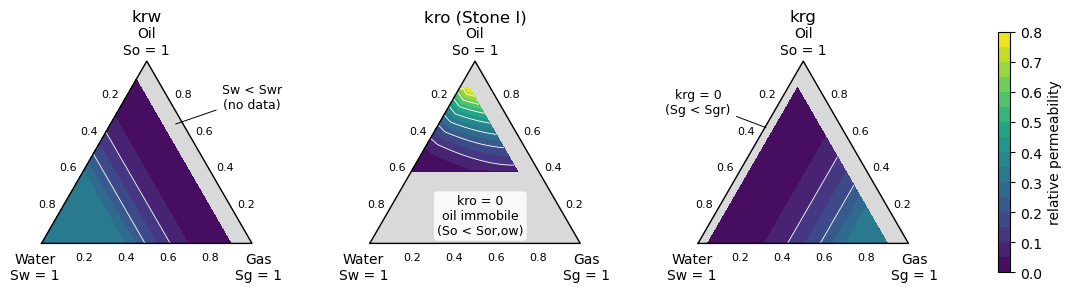

In [33]:
import matplotlib.pyplot as plt
from matplotlib.tri import Triangulation

H = np.sqrt(3) / 2
def to_xy(sw, sg, so):
    """Water = bottom-left, Gas = bottom-right, Oil = top."""
    return sg + 0.5 * so, H * so

x, y = to_xy(Sw, Sg, So)
tri = Triangulation(x, y)
levels = np.r_[1e-6, np.linspace(0.05, 0.8, 16)]     # kr = 0 is NOT filled -> stays grey
GREY = "#d9d9d9"
box = dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85)

fig, axs = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, z, title in zip(axs, (krw, kro, krg), ("krw", "kro (Stone I)", "krg")):
    ax.fill([0, 1, 0.5], [0, 0, H], color=GREY, zorder=0)           # background = "phase not mobile"
    cf = ax.tricontourf(tri, z, levels=levels, cmap="viridis", vmin=0, vmax=0.8, zorder=1)
    ax.tricontour(tri, z, levels=np.arange(0.1, 0.8, 0.1), colors="w", linewidths=0.6, zorder=2)

    ax.plot([0, 1, 0.5, 0], [0, 0, H, 0], "k", lw=1, zorder=3)
    ax.text(-0.03, -0.04, "Water\nSw = 1", ha="center", va="top")
    ax.text(1.03, -0.04, "Gas\nSg = 1", ha="center", va="top")
    ax.text(0.5, H + 0.02, "Oil\nSo = 1", ha="center", va="bottom")
    for t in (0.2, 0.4, 0.6, 0.8):
        ax.text(t, -0.04, f"{t:.1f}", ha="center", va="top", fontsize=8)
        xl, yl = to_xy(t, 0, 1 - t);  ax.text(xl - 0.03, yl, f"{t:.1f}", ha="right", fontsize=8)
        xr, yr = to_xy(0, 1 - t, t);  ax.text(xr + 0.03, yr, f"{t:.1f}", ha="left", fontsize=8)
    ax.set_title(title); ax.set_aspect("equal"); ax.axis("off")
    ax.set_xlim(-0.15, 1.15); ax.set_ylim(-0.15, H + 0.15)

# --- text in the regions where the phase cannot flow (kr = 0 -> grey) ---
line = dict(arrowstyle="-", color="k", lw=0.7)
axs[0].annotate("Sw < Swr\n(no data)", xy=to_xy(0.05, 0.3, 0.65), xytext=(1.0, 0.64),
                ha="center", fontsize=9, bbox=box, arrowprops=line)
axs[1].text(*to_xy(0.4, 0.45, 0.15), "kro = 0\noil immobile\n(So < Sor,ow)",
            ha="center", va="center", fontsize=9, bbox=box)
axs[2].annotate("krg = 0\n(Sg < Sgr)", xy=to_xy(0.35, 0.02, 0.63), xytext=(0.0, 0.62),
                ha="center", fontsize=9, bbox=box, arrowprops=line)

fig.colorbar(cf, ax=axs, shrink=0.6, label="relative permeability")
plt.show()